# Módulo 1 · El objeto `Raw` y la estructura `Info`

**Objetivo:** abrir un EDF de TUSZ y saber responder a: ¿qué canales hay?, ¿de qué tipo?,
¿a qué frecuencia?, ¿cuánto dura?, ¿cómo saco los datos como array de NumPy?

Al final de este módulo tendrás una función que lee cualquier EDF de TUSZ con
nombres de canal limpios.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

mne.set_log_level("WARNING")
from tusz_utils import TUSZ_ROOT, SALIDAS
EDF = TUSZ_ROOT / "edf/train/aaaaabqv/s001_2004/02_tcp_le/aaaaabqv_s001_t000.edf"

## 1.1 Leer un EDF: `preload`

`mne.io.read_raw_edf()` puede funcionar de dos maneras:

- `preload=False` (por defecto): solo lee la **cabecera**. Los datos se leen del disco
  cuando los pides. Ideal para explorar cientos de ficheros sin llenar la RAM.
- `preload=True`: carga toda la señal en memoria. **Obligatorio** para filtrar,
  cambiar referencia, remuestrear…

In [2]:
raw = mne.io.read_raw_edf(EDF, preload=False)
print(raw.preload)
raw.load_data()          # equivale a haber usado preload=True
print(raw.preload)

False
True


## 1.2 `raw.info`: los metadatos

`Info` se comporta como un diccionario. Los campos que más vas a usar:

In [3]:
print(raw.info)

<Info | 8 non-empty values
 bads: []
 ch_names: EEG FP1-LE, EEG FP2-LE, EEG F3-LE, EEG F4-LE, EEG C3-LE, EEG ...
 chs: 33 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: 2004-01-01 00:00:00 UTC
 nchan: 33
 projs: []
 sfreq: 250.0 Hz
 subject_info: <subject_info | his_id: aaaaabqv, sex: 2, last_name: aaaaabqv>
>


In [4]:
info = raw.info
print("Frecuencia de muestreo:", info["sfreq"], "Hz")
print("Nº de canales:        ", info["nchan"])
print("Filtros del equipo:    highpass", info["highpass"], "Hz / lowpass", info["lowpass"], "Hz")
print("Fecha (anonimizada):  ", info["meas_date"])
print("Sujeto:               ", info["subject_info"])

Frecuencia de muestreo: 250.0 Hz
Nº de canales:         33
Filtros del equipo:    highpass 0.0 Hz / lowpass 125.0 Hz
Fecha (anonimizada):   2004-01-01 00:00:00+00:00
Sujeto:                <subject_info | his_id: aaaaabqv, sex: 2, last_name: aaaaabqv>


> **Ojo con `lowpass = 125 Hz`**: no es que el equipo filtrara a 125 Hz, es la
> frecuencia de Nyquist (250/2). El EDF no guarda el filtro real.

### Duración y eje temporal

In [5]:
print("Muestras:", raw.n_times)
print("Duración:", raw.times[-1], "s  =", raw.times[-1] / 60, "min")
print("raw.times:", raw.times[:5], "...")   # vector de tiempos en segundos

Muestras: 359250
Duración: 1436.996 s  = 23.949933333333334 min
raw.times: [0.    0.004 0.008 0.012 0.016] ...


## 1.3 Canales: nombres y tipos

In [6]:
print(raw.ch_names)

['EEG FP1-LE', 'EEG FP2-LE', 'EEG F3-LE', 'EEG F4-LE', 'EEG C3-LE', 'EEG C4-LE', 'EEG A1-LE', 'EEG A2-LE', 'EEG P3-LE', 'EEG P4-LE', 'EEG O1-LE', 'EEG O2-LE', 'EEG F7-LE', 'EEG F8-LE', 'EEG T3-LE', 'EEG T4-LE', 'EEG T5-LE', 'EEG T6-LE', 'EEG FZ-LE', 'EEG CZ-LE', 'EEG PZ-LE', 'EEG OZ-LE', 'EEG PG1-LE', 'EEG PG2-LE', 'EEG EKG-LE', 'EEG SP2-LE', 'EEG SP1-LE', 'EEG RLC-LE', 'EEG LUC-LE', 'EEG 30-LE', 'EEG T1-LE', 'EEG T2-LE', 'PHOTIC PH']


In [7]:
pd.Series(raw.get_channel_types()).value_counts()

eeg    33
Name: count, dtype: int64

El EDF dice que **todo es EEG**, pero no es verdad: hay EKG, fotoestimulación (`PHOTIC`),
canales sin usar (`30`, `PG1`…). Además los nombres traen ruido (`EEG ` delante y `-LE`
detrás, porque este fichero está referenciado a las orejas unidas — *linked ears*).
En otros ficheros de TUSZ verás `-REF` (montaje AR, *average reference*).

### Limpiar nombres con `rename_channels`
Acepta un diccionario o **una función** que se aplica a cada nombre:

In [8]:
import re

def clean_name(ch):
    ch = re.sub(r"^EEG\s+", "", ch.strip())          # quita 'EEG ' del principio
    ch = re.sub(r"(-LE|-REF|\s+PH)$", "", ch)        # quita el sufijo de referencia
    return ch.upper()

raw.rename_channels(clean_name)
print(raw.ch_names)

['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'A1', 'A2', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'FZ', 'CZ', 'PZ', 'OZ', 'PG1', 'PG2', 'EKG', 'SP2', 'SP1', 'RLC', 'LUC', '30', 'T1', 'T2', 'PHOTIC']


### Corregir tipos con `set_channel_types`
El tipo importa: muchas funciones (filtrado, referencia, ICA, `pick("eeg")`) solo
actúan sobre los canales del tipo correcto.

In [9]:
EEG_1020 = {"FP1", "FP2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2", "F7", "F8",
            "T3", "T4", "T5", "T6", "A1", "A2", "FZ", "CZ", "PZ", "OZ", "T1", "T2"}

def guess_type(ch):
    if ch in EEG_1020:            return "eeg"
    if ch.startswith(("EKG", "ECG")): return "ecg"
    if ch in {"ROC", "LOC"}:      return "eog"
    if ch.startswith("EMG"):      return "emg"
    return "misc"

raw.set_channel_types({ch: guess_type(ch) for ch in raw.ch_names}, on_unit_change="ignore")
pd.Series(raw.get_channel_types(), index=raw.ch_names).groupby(lambda c: guess_type(c)).size()

ecg      1
eeg     24
misc     8
dtype: int64

## 1.4 Seleccionar canales: `pick`, `drop_channels`

`pick` acepta **tipos** (`"eeg"`, `"ecg"`), **nombres** o **índices**.
Recuerda: modifica el objeto, así que usamos `.copy()`.

In [10]:
solo_eeg = raw.copy().pick("eeg")
print(len(solo_eeg.ch_names), solo_eeg.ch_names)

frontales = raw.copy().pick(["FP1", "FP2", "F3", "F4", "F7", "F8", "FZ"])
print(frontales.ch_names)

sin_misc = raw.copy().drop_channels([c for c, t in zip(raw.ch_names, raw.get_channel_types()) if t == "misc"])
print(sin_misc.ch_names)

24 ['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'A1', 'A2', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'FZ', 'CZ', 'PZ', 'OZ', 'T1', 'T2']
['FP1', 'FP2', 'F3', 'F4', 'F7', 'F8', 'FZ']
['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'A1', 'A2', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'FZ', 'CZ', 'PZ', 'OZ', 'EKG', 'T1', 'T2']


## 1.5 Recortar en el tiempo: `crop`

La primera crisis de ausencia de este fichero empieza en **t ≈ 179.9 s** (lo veremos en el módulo 3).
Vamos a quedarnos con un trozo de 30 s alrededor:

In [11]:
trozo = raw.copy().crop(tmin=170, tmax=200)
print(trozo.times[0], trozo.times[-1], trozo.n_times)
print("first_time (s desde el inicio del fichero original):", trozo.first_time)

0.0 30.0 7501
first_time (s desde el inicio del fichero original): 170.0


> **`first_samp` / `first_time`**: tras `crop`, `trozo.times` vuelve a empezar en 0,
> pero MNE recuerda dónde estaba en el original. Lo agradecerás al alinear anotaciones.

## 1.6 Sacar los datos como NumPy

Tres formas, de más a menos recomendada:

In [12]:
# (a) get_data: la más clara. Devuelve (n_canales, n_muestras) en VOLTIOS
data = raw.get_data(picks="eeg", tmin=170, tmax=200)
print(data.shape, data.dtype)

# Con unidades: µV
data_uv = raw.get_data(picks="eeg", tmin=170, tmax=200, units="uV")
print(f"Rango: {data_uv.min():.0f} a {data_uv.max():.0f} µV")

(24, 7500) float64
Rango: -891 a 1073 µV


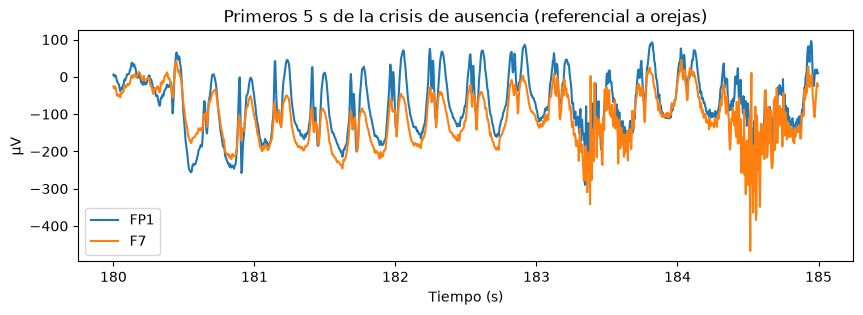

In [13]:
# (b) return_times=True para tener también el eje temporal
data, times = raw.get_data(picks=["FP1", "F7"], tmin=180, tmax=185, return_times=True)
plt.figure(figsize=(10, 3))
plt.plot(times, data.T * 1e6)
plt.legend(["FP1", "F7"]); plt.xlabel("Tiempo (s)"); plt.ylabel("µV")
plt.title("Primeros 5 s de la crisis de ausencia (referencial a orejas)")
plt.show()

In [14]:
# (c) Indexado tipo NumPy: raw[canales, muestras] -> (datos, tiempos)
sf = raw.info["sfreq"]
d, t = raw[["FP1", "FP2"], int(180 * sf):int(181 * sf)]
print(d.shape, t[:3])

(2, 250) [180.    180.004 180.008]


### A pandas
Útil para inspeccionar o para estadísticas rápidas (no para datasets grandes):

In [15]:
df = raw.to_data_frame(picks="eeg", start=int(180 * sf), stop=int(190 * sf))   # en µV por defecto
df.describe().T.head(8)

,count,mean,std,min,25%,50%,75%,max
time,2500.0,184.998000,2.887329,180.000000,182.499000,184.998000,187.497000,189.996000
FP1,2500.0,-39.389669,89.358003,-289.917142,-107.193049,-26.702895,30.593888,184.326267
FP2,2500.0,-19.076426,92.330520,-248.413215,-86.669967,-10.223394,53.710965,205.688583
F3,2500.0,-16.741098,120.296138,-671.692242,-89.111374,9.613042,72.937049,245.361455
F4,2500.0,-9.093144,118.102566,-600.891424,-77.209513,12.817389,74.157753,278.320457
C3,2500.0,-20.344615,97.798516,-825.806091,-62.561068,-12.817389,32.043474,379.028516
C4,2500.0,-0.760743,87.884504,-515.136985,-49.133326,2.288820,46.691919,306.701819
A1,2500.0,-49.666774,15.025883,-110.168514,-58.898956,-50.659206,-41.503928,18.005380


## 1.7 Guardar en formato FIF

El formato nativo de MNE (`.fif`) guarda señal + `Info` + anotaciones. Es mucho más rápido de
leer que el EDF y conserva todo lo que hayas cambiado (nombres, tipos, filtros…).
Por convención los ficheros Raw acaban en `_raw.fif` o `_eeg.fif`.

In [16]:
out_dir = SALIDAS
trozo.save(out_dir / "aaaaabqv_crisis1_raw.fif", overwrite=True)
mne.io.read_raw_fif(out_dir / "aaaaabqv_crisis1_raw.fif")

<Raw | aaaaabqv_crisis1_raw.fif, 33 x 7501 (30.0 s), ~32 KiB, data not loaded>

---
## 🧪 Ejercicios

**E1.1** Abre el fichero `aaaaamtc_s001_t000` (montaje `01_tcp_ar`, ruta
`edf/train/aaaaamtc/s001_2012/01_tcp_ar/`). ¿Qué sufijo tienen los canales? ¿Cuántos canales
hay de cada tipo después de limpiar nombres y tipos?

**E1.2** Para el fichero de ejemplo, calcula la **amplitud pico a pico** (máx − mín, en µV) de
cada canal EEG en dos tramos de 7 s: dentro de la crisis (180-187 s) y antes (100-107 s).
¿En qué canales aumenta más?

**E1.3** Escribe una función `leer_tusz(ruta_edf)` que haga en una sola llamada: leer con
`preload=True`, limpiar nombres y corregir tipos. (Esta función ya existe en `tusz_utils.py`
como `read_tusz_raw`, compárala con la tuya.)

### Solución E1.1

In [17]:
edf2 = TUSZ_ROOT / "edf/train/aaaaamtc/s001_2012/01_tcp_ar/aaaaamtc_s001_t000.edf"
r2 = mne.io.read_raw_edf(edf2)
print(r2.ch_names[:4], "...")       # sufijo -REF
r2.rename_channels(clean_name)
r2.set_channel_types({c: guess_type(c) for c in r2.ch_names}, on_unit_change="ignore")
pd.Series(r2.get_channel_types()).value_counts()

['EEG FP1-REF', 'EEG FP2-REF', 'EEG F3-REF', 'EEG F4-REF'] ...


eeg     23
misc     9
eog      2
ecg      1
emg      1
Name: count, dtype: int64

### Solución E1.2

In [18]:
def ptp_uv(raw, tmin, tmax):
    x = raw.get_data(picks="eeg", tmin=tmin, tmax=tmax, units="uV")
    return pd.Series(x.max(1) - x.min(1), index=raw.copy().pick("eeg").ch_names)

comp = pd.DataFrame({"antes": ptp_uv(raw, 100, 107), "crisis": ptp_uv(raw, 180, 187)})
comp["ratio"] = comp.crisis / comp.antes
comp.sort_values("ratio", ascending=False).round(1)

,antes,crisis,ratio
C3,122.7,1204.8,9.8
T3,87.6,658.9,7.5
T5,87.6,604.6,6.9
F4,140.7,879.2,6.2
F3,149.5,917.1,6.1
C4,136.1,821.8,6.0
P3,128.2,738.8,5.8
T4,94.3,522.2,5.5
T6,109.3,546.9,5.0
T2,56.5,266.1,4.7


### Solución E1.3

In [19]:
def leer_tusz(ruta_edf):
    r = mne.io.read_raw_edf(ruta_edf, preload=True)
    r.rename_channels(clean_name)
    r.set_channel_types({c: guess_type(c) for c in r.ch_names}, on_unit_change="ignore")
    return r

leer_tusz(EDF)

<RawEDF | aaaaabqv_s001_t000.edf, 33 x 359250 (1437.0 s), ~90.5 MiB, data loaded>